# Evaluating and Improving the Robustness of Deep-Learning MSA Selection to Candidate-Pool Composition
**Hanane Wazneh, Zahraa Hussein** · CMPS 355 Graduate Research Project · Supplementary notebook

This notebook reproduces every result in the manuscript. Cells are in run order; the outputs shown are from our runs.

**Before running:** nothing is needed beyond a Google account. Section 2 downloads the authors' code and data; all inputs and outputs are kept in the Drive folder `MyDrive/MSA_Model2_Project`.

**Runtime on free Colab (2 CPU cores):** candidate generation is the slow step (PRANK 1.5–3.4 h per dataset). Each step saves its results to Drive and skips work already done, so after a Colab restart run Section 1 again and continue from where it stopped.

| Section | Step | Manuscript |
|---|---|---|
| 1 | Setup: tools and Drive | 2.9 |
| 2 | Get the authors' code, model and datasets 23410 and 126014 | 2.1–2.2 |
| 2b | Validate the pre-trained model (ρ = 0.995 on 126014; ρ = 0.959 on 23410) | 2.1 |
| 3 | Template tree of 23410 (50 taxa, total branch length 22.04) and INDELible calibration | 2.2 |
| 4 | Simulate SIM01–SIM03 | 2.2 |
| 5 | Clean the simulated datasets | 2.2 |
| 6 | Authors' documented commands, then generate candidates (GUIDANCE2-MAFFT, GUIDANCE2-PRANK, Muscle5) | 2.3 |
| 7 | Extract features and dseq | 2.4 |
| 8 | Part A and the fixed-reference fix (3,500 pools) | 2.5–2.7, 3.1–3.4 |
| 9 | Bootstrap statistics (Table 3, Supplementary Table S1) | 2.8 |
| 10 | Figures 1 and 2 | 3 |
| 11 | Implementation check and reference without PRANK | 3.5 |
| 12 | Package the supplementary material | — |

Section 2b contains the model-reproduction checks reported in Section 2.1 of the manuscript (Spearman ρ = 0.995 against the authors' predictions for 126014; ρ = 0.959 with dseq for 23410).

## 1. Setup
Mounts Google Drive and installs INDELible, MAFFT, PRANK, Muscle5, BioPerl and GUIDANCE2. The compiled GUIDANCE2 is saved to Drive and reused after a restart. **Run this first after every Colab restart.**

In [1]:
import subprocess, sys
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

def sh(c):
    return subprocess.run(c, shell=True, capture_output=True, text=True)

sh("apt-get update -qq")
r = sh("apt-get install -y -qq indelible mafft prank muscle bioperl libbio-procedural-perl")
print("apt install:", "OK" if r.returncode == 0 else r.stderr[-500:])
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython", "pandas"])

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
gtar = proj / "tools/guidance_compiled.tar.gz"
G = Path("/content/GUIDANCE")
if not (G / "www/Guidance/guidance.pl").exists():
    if gtar.exists():
        sh(f"tar -xzf '{gtar}' -C /content")
    else:
        sh("git clone -q --depth 1 https://github.com/HaimAshk/GUIDANCE.git /content/GUIDANCE")
        r = sh("cd /content/GUIDANCE && make -s")
        print("compile GUIDANCE:", "OK" if r.returncode == 0 else r.stderr[-500:])
        (proj / "tools").mkdir(exist_ok=True)
        sh(f"tar -czf '{gtar}' -C /content GUIDANCE")

for t in ["indelible", "mafft", "prank", "muscle"]:
    print(f"{t:10}", sh(f"which {t}").stdout.strip() or "MISSING")
print("bioperl   ", "OK" if sh("perl -MBio::Perl -MBio::SeqIO -e 1").returncode == 0 else "MISSING")
print("guidance  ", "OK" if (G / "www/Guidance/guidance.pl").exists() else "MISSING")

Mounted at /content/drive
apt install: OK
indelible  /usr/bin/indelible
mafft      /usr/bin/mafft
prank      /usr/bin/prank
muscle     /usr/bin/muscle
bioperl    OK
guidance   OK


## 2. Get the authors' code, model and example datasets
Clones the authors' repository, saves a copy to Drive (pre-trained Model 2, feature-extraction code, dataset 23410), and recovers the feature table of dataset 126014 from the repository's `model` branch. Skips anything already on Drive. Expected output: `126014 features: (1605, 158)`.

In [2]:
import subprocess, shutil
from pathlib import Path
from io import StringIO
import pandas as pd

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

proj = Path("/content/drive/MyDrive/MSA_Model2_Project"); proj.mkdir(parents=True, exist_ok=True)
local_repo = Path("/content/sp_alternative")
drive_repo = proj / "sp_alternative"

# 1) The authors' repository (full clone: the 126014 features live on its 'model' branch)
if not local_repo.exists():
    subprocess.run(["git", "clone", "https://github.com/nimrodSerokTAU/sp_alternative.git",
                    str(local_repo)], check=True)
if not drive_repo.exists():
    shutil.copytree(local_repo, drive_repo)
print("Repository on Drive:", drive_repo.exists())

# 2) Features of dataset 126014, recovered from the 'model' branch
out = proj / "126014_features_recovered.csv"
if not out.exists():
    r = subprocess.run(["git", "show", "origin/model:example_data/features/126014_features.csv"],
                       cwd=local_repo, capture_output=True, text=True, check=True)
    pd.read_csv(StringIO(r.stdout)).to_csv(out, index=False)
df = pd.read_csv(out, low_memory=False)
print("126014 features:", df.shape, "| dseq column present:", "dseq_from_true" in df.columns)


Repository on Drive: True
126014 features: (1605, 158) | dseq column present: True


## 2b. Validate the pre-trained model (manuscript 2.1)
Checks that our setup reproduces the authors' Model 2. Code and outputs are taken unchanged from our development notebook.

**Dataset 126014.** Runs Model 2 with the saved rank scaler inside the pool and compares with the predictions released by the authors (A: Spearman ρ = 0.995, same top-ranked MSA; B, C: maximum absolute difference 0.118, also when using the authors' own script). The remaining difference is likely due to the scikit-learn version (1.5.1 → 1.6.1; see the warning).


In [ ]:
import os, sys, io, subprocess
import numpy as np, pandas as pd, tensorflow as tf

REPO = "/content/sp_alternative"
os.chdir(REPO); sys.path.insert(0, REPO)
from dl_model.data_processing.group_aware_zscore_scaler import GroupAwareScalerZ

MODEL  = f"{REPO}/dl_model/input/orthomam_model2/regressor_model_0_mode1_dseq_from_true.keras"
SCALER = f"{REPO}/dl_model/input/orthomam_model2/scaler_0_mode1_dseq_from_true.pkl"

# 1. Get family 126014 features from the `model` branch
raw = subprocess.run(
    ["git", "show", "origin/model:example_data/features/126014_features.csv"],
    capture_output=True, text=True, check=True).stdout
f = pd.read_csv(io.StringIO(raw))
f = f.drop(columns=["rf_from_true"], errors="ignore")
f = f.loc[:, ~f.columns.str.startswith("Unnamed")]
f["code"] = f["code"].astype(str)
f["code1"] = f["code1"].astype(str)
f = f[f["code"] != f["code1"]].reset_index(drop=True)   # remove the reference row

# 2. Run Model 2 (rank scaler inside the pool)
scaler = GroupAwareScalerZ(mode="rank", use_global=False); scaler.load(SCALER)
model = tf.keras.models.load_model(MODEL, compile=False)
X = f[list(scaler.feature_names)].copy()
X["code1"] = f["code1"].values
mine = model.predict(scaler.transform(X), verbose=0).reshape(-1)

# 3. Compare with the authors' saved predictions
shipped = pd.read_csv(f"{REPO}/example_data/predictions/prediction_pretrained_126014_mode1_dseq_from_true.csv")
m = f[["code"]].assign(mine=mine).merge(shipped[["code", "predicted_score"]], on="code")
print("rows compared:", len(m))
print("max difference:", np.abs(m["mine"] - m["predicted_score"]).max())

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


rows compared: 1604
max difference: 0.11810612678527832


In [ ]:
from scipy.stats import spearmanr
import subprocess

# A) How different are they overall?
print("A) mean abs diff:", np.abs(m["mine"] - m["predicted_score"]).mean())
print("A) Spearman:", spearmanr(m["mine"], m["predicted_score"]).statistic)
print("A) same top pick:",
      m.loc[m["mine"].idxmin(), "code"] == m.loc[m["predicted_score"].idxmin(), "code"])

# B) Keep the reference row in the pool
full = pd.read_csv(io.StringIO(raw))
full = full.drop(columns=["rf_from_true"], errors="ignore")
full = full.loc[:, ~full.columns.str.startswith("Unnamed")]
full["code"] = full["code"].astype(str); full["code1"] = full["code1"].astype(str)
XB = full[list(scaler.feature_names)].copy(); XB["code1"] = full["code1"].values
pB = model.predict(scaler.transform(XB), verbose=0).reshape(-1)
mB = full[["code"]].assign(mine=pB).merge(shipped[["code", "predicted_score"]], on="code")
print("B) rows:", len(mB), "max diff:", np.abs(mB["mine"] - mB["predicted_score"]).max())

# C) Run the authors' own script on the same file
full.to_csv("/content/f126014.csv", index=False)
subprocess.run([
    "python", "dl_model/scripts/predict_pretrained_main.py",
    "--features-file", "/content/f126014.csv",
    "--true-score-name", "dseq_from_true", "--mode", "1",
    "--scaler-type-features", "rank", "--scaler-type-labels", "rank",
    "--model-path", MODEL, "--scaler-path", SCALER,
    "--out-dir", "/content/check126014", "--run-id", "check"],
    cwd=REPO)
C = pd.read_csv("/content/check126014/prediction_pretrained_check_mode1_dseq_from_true.csv")
mC = C[["code", "predicted_score"]].merge(
    shipped[["code", "predicted_score"]], on="code", suffixes=("_script", "_shipped"))
print("C) rows:", len(mC), "max diff:",
      np.abs(mC["predicted_score_script"] - mC["predicted_score_shipped"]).max())

A) mean abs diff: 0.03478436219852017
A) Spearman: 0.9952007290571269
A) same top pick: True
B) rows: 1604 max diff: 0.11824542284011841
C) rows: 1604 max diff: 0.11824542284011841


**Dataset 23410.** Prepares the feature table (adds the pool identifier `code1`, removes columns the preprocessing cannot use), runs the authors' prediction script with rank scaling, and correlates the predicted scores with dseq over the whole pool (Spearman ρ = 0.959). The per-source correlations are shown for reference.


In [ ]:

import pandas as pd
from pathlib import Path

source = Path(
    "/content/sp_alternative/example_data/features/groups_final/unified_stats_23410.csv"
)
output = Path("/content/unified_stats_23410_prediction.csv")

df = pd.read_csv(source)

# Remove columns that would cause preprocessing problems
df = df.drop(columns=["Unnamed: 157", "rf_from_true"], errors="ignore")

# Identify the candidate pool
df["code1"] = "23410"

df.to_csv(output, index=False)

print("Saved:", output)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing values:", int(df.isna().sum().sum()))


Saved: /content/unified_stats_23410_prediction.csv
Rows: 1605
Columns: 158
Missing values: 0


In [ ]:

%cd /content/sp_alternative

!python dl_model/scripts/predict_pretrained_main.py \
  --features-file /content/unified_stats_23410_prediction.csv \
  --true-score-name dseq_from_true \
  --mode 1 \
  --scaler-type-features rank \
  --scaler-type-labels rank \
  --model-path /content/sp_alternative/dl_model/input/orthomam_model2/regressor_model_0_mode1_dseq_from_true.keras \
  --scaler-path /content/sp_alternative/dl_model/input/orthomam_model2/scaler_0_mode1_dseq_from_true.pkl \
  --out-dir /content/model2_official_test \
  --run-id pool_23410


/content/sp_alternative
I0000 00:00:1792926504.366773    2862 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792926504.581605    2862 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792926510.654289    2862 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
[pretrained] reading: /content/unified_stats_23410_prediction.csv
[pretrained] rows after preprocess: 1605
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persis

In [ ]:
import pandas as pd
from scipy.stats import spearmanr

features_path = "/content/sp_alternative/example_data/features/groups_final/unified_stats_23410.csv"
pred_path = "/content/model2_official_test/prediction_pretrained_pool_23410_mode1_dseq_from_true.csv"

df = pd.read_csv(features_path)
pred = pd.read_csv(pred_path)

df = df.merge(pred[["code", "predicted_score"]], on="code", how="inner")
df["candidate_type"] = df["code"].str.split(".").str[0]

for group in ["MUSCLE_diversified_replicate", "bali_phy_msa"]:
    subset = df[df["candidate_type"] == group]
    # Lower dseq is better; compare with the model's predicted score.
    rho = spearmanr(subset["dseq_from_true"], subset["predicted_score"]).statistic
    print(f"{group}: n={len(subset)}, Spearman correlation={rho:.4f}")

MUSCLE_diversified_replicate: n=400, Spearman correlation=0.9480
bali_phy_msa: n=400, Spearman correlation=0.5242


In [ ]:
print(df[["dseq_from_true", "predicted_score"]].corr(method="spearman"))

                 dseq_from_true  predicted_score
dseq_from_true         1.000000         0.959373
predicted_score        0.959373         1.000000


## 3. INDELible calibration
Two grids, compared with dataset 23410 (486 columns, gap fraction 0.814). The first, coarse grid narrows the range; the second uses 5 seeds per setting. Chosen: root length 100, indel rate 0.025 (mean gap fraction 0.816).

**Template tree and target alignment.** Inspects the 50-taxon tree of 23410 used for simulation (total branch length 22.04) and the target statistics of its true alignment (486 columns, gap fraction 0.814).


In [ ]:
import subprocess, sys

# 0) Reinstall packages lost in the restart
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython"], check=True)

from pathlib import Path
from Bio import Phylo, SeqIO

# 1) Install INDELible
cmd = "lsb_release -ds; apt-get update -qq; apt-get install -y -qq indelible 2>&1 | tail -3; which indelible"
print(subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout)

# 2) Inspect the 23410 tree and true alignment
fam = Path("/content/drive/MyDrive/MSA_Model2_Project/sp_alternative/example_data/alternative_msas/23410")

tree_text = (fam / "23410_true_tree.txt").read_text().strip()
print("Tree file starts with:", tree_text[:150])

tree = Phylo.read(str(fam / "23410_true_tree.txt"), "newick")
leaves = tree.get_terminals()
print("\nNumber of taxa:", len(leaves))
print("Total branch length:", round(tree.total_branch_length(), 3))

true_msa = list(SeqIO.parse(str(fam / "23410_TRUE.fas"), "fasta"))
n_cols = len(true_msa[0].seq)
gaps = sum(str(r.seq).count("-") for r in true_msa) / (len(true_msa) * n_cols)
print("\nTrue alignment: sequences =", len(true_msa), "| columns =", n_cols, "| gap fraction =", round(gaps, 3))

Ubuntu 24.04.5 LTS
Unpacking indelible (1.03-6) ...
Setting up indelible (1.03-6) ...
Processing triggers for man-db (2.12.0-4build2) ...
/usr/bin/indelible

Tree file starts with: ((((((((((((Cavia_porcellus:0.29194,Fukomys_damarensis:0.17472):0.16828,Marmota_marmota_marmota:0.18606):0.03319,(((((((Arvicola_amphibius:0.23846,Mic

Number of taxa: 50
Total branch length: 22.037

True alignment: sequences = 50 | columns = 486 | gap fraction = 0.814


In [ ]:
# ---------- SETUP (rerun this block after every restart) ----------
import subprocess, sys, os
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython", "pandas"], check=True)
if subprocess.run("which indelible", shell=True, capture_output=True).returncode != 0:
    subprocess.run("apt-get update -qq; apt-get install -y -qq indelible", shell=True)
print("indelible:", subprocess.run("which indelible", shell=True, capture_output=True, text=True).stdout.strip())

# ---------- CALIBRATION ----------
import itertools, statistics
import pandas as pd
from Bio import SeqIO

fam = Path("/content/drive/MyDrive/MSA_Model2_Project/sp_alternative/example_data/alternative_msas/23410")
tree = "".join((fam / "23410_true_tree.txt").read_text().split())
if not tree.endswith(";"):
    tree += ";"

work = Path("/content/sim_test"); work.mkdir(exist_ok=True)

def simulate(root_len, indel_rate, seed, name):
    ctrl = f"""[TYPE] AMINOACID 1
[SETTINGS]
  [randomseed] {seed}
  [output] FASTA
  [fastaextension] fas
[MODEL] m
  [submodel] WAG
  [rates] 0 1.0 8
  [indelmodel] POW 1.7 500
  [indelrate] {indel_rate}
[TREE] t {tree}
[PARTITIONS] p [t m {root_len}]
[EVOLVE] p 1 {name}
"""
    (work / "control.txt").write_text(ctrl)
    r = subprocess.run(["indelible", "control.txt"], cwd=work, capture_output=True, text=True)
    out = work / f"{name}_TRUE.fas"
    if not out.exists():
        print("FAILED", root_len, indel_rate, r.stdout[-300:], r.stderr[-300:])
        return None
    seqs = [str(s.seq) for s in SeqIO.parse(str(out), "fasta")]
    cols = len(seqs[0])
    gap = sum(s.count("-") for s in seqs) / (len(seqs) * cols)
    mean_len = statistics.mean(len(s.replace("-", "")) for s in seqs)
    return len(seqs), cols, round(gap, 3), round(mean_len)

rows = []
for root_len, rate in itertools.product([100, 150, 200], [0.02, 0.05, 0.1]):
    res = simulate(root_len, rate, seed=7, name=f"cal_{root_len}_{rate}")
    if res:
        rows.append(dict(root_len=root_len, indel_rate=rate, taxa=res[0],
                         columns=res[1], gap_fraction=res[2], mean_seq_len=res[3]))

df = pd.DataFrame(rows)
print("\nTARGET (family 23410): columns = 486, gap fraction = 0.814, mean sequence length = about 90\n")
print(df.to_string(index=False))

Mounted at /content/drive
indelible: /usr/bin/indelible

TARGET (family 23410): columns = 486, gap fraction = 0.814, mean sequence length = about 90

 root_len  indel_rate  taxa  columns  gap_fraction  mean_seq_len
      100        0.02    50      417         0.762            99
      100        0.05    50      606         0.842            96
      100        0.10    50     1361         0.955            61
      150        0.02    50     1505         0.884           175
      150        0.05    50     2132         0.922           165
      150        0.10    50     2035         0.925           153
      200        0.02    50     1163         0.767           271
      200        0.05    50     2764         0.895           289
      200        0.10    50     4536         0.947           242


In [ ]:
# ---------- SETUP (safe to rerun) ----------
import subprocess, sys, itertools, statistics
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython", "pandas"], check=True)
if subprocess.run("which indelible", shell=True, capture_output=True).returncode != 0:
    subprocess.run("apt-get update -qq; apt-get install -y -qq indelible", shell=True)

import pandas as pd
from Bio import SeqIO

fam = Path("/content/drive/MyDrive/MSA_Model2_Project/sp_alternative/example_data/alternative_msas/23410")
tree = "".join((fam / "23410_true_tree.txt").read_text().split())
if not tree.endswith(";"):
    tree += ";"
work = Path("/content/sim_test"); work.mkdir(exist_ok=True)

def simulate(root_len, indel_rate, seed, name):
    ctrl = f"""[TYPE] AMINOACID 1
[SETTINGS]
  [randomseed] {seed}
  [output] FASTA
  [fastaextension] fas
[MODEL] m
  [submodel] WAG
  [rates] 0 1.0 8
  [indelmodel] POW 1.7 500
  [indelrate] {indel_rate}
[TREE] t {tree}
[PARTITIONS] p [t m {root_len}]
[EVOLVE] p 1 {name}
"""
    (work / "control.txt").write_text(ctrl)
    subprocess.run(["indelible", "control.txt"], cwd=work, capture_output=True, text=True)
    out = work / f"{name}_TRUE.fas"
    if not out.exists():
        return None
    seqs = [str(s.seq) for s in SeqIO.parse(str(out), "fasta")]
    cols = len(seqs[0])
    gap = sum(s.count("-") for s in seqs) / (len(seqs) * cols)
    mean_len = statistics.mean(len(s.replace("-", "")) for s in seqs)
    return cols, gap, mean_len

# ---------- NARROW GRID, 5 SEEDS EACH ----------
rows = []
for root_len, rate in itertools.product([90, 100, 110], [0.025, 0.03, 0.035, 0.04]):
    res = [simulate(root_len, rate, seed, f"g_{root_len}_{rate}_{seed}") for seed in range(1, 6)]
    res = [r for r in res if r]
    if not res:
        continue
    cols = [r[0] for r in res]
    rows.append(dict(
        root_len=root_len, indel_rate=rate, runs=len(res),
        cols_mean=round(statistics.mean(cols)),
        cols_range=f"{min(cols)}-{max(cols)}",
        gap_mean=round(statistics.mean(r[1] for r in res), 3),
        seqlen_mean=round(statistics.mean(r[2] for r in res)),
    ))

df = pd.DataFrame(rows)
print("TARGET (family 23410): columns = 486, gap fraction = 0.814, mean sequence length = about 90\n")
print(df.to_string(index=False))

TARGET (family 23410): columns = 486, gap fraction = 0.814, mean sequence length = about 90

 root_len  indel_rate  runs  cols_mean cols_range  gap_mean  seqlen_mean
       90       0.025     5        288    147-485     0.698           80
       90       0.030     5        568    259-806     0.813           96
       90       0.035     5        911   298-1921     0.834          105
       90       0.040     5        701   329-1442     0.849           94
      100       0.025     5        574    311-811     0.816           97
      100       0.030     5        578   158-1025     0.829           91
      100       0.035     5        684   200-1069     0.862           91
      100       0.040     5        848   165-1341     0.869           93
      110       0.025     5        857   232-1378     0.767          149
      110       0.030     5        723   402-1141     0.812          128
      110       0.035     5       1245   361-2962     0.827          182
      110       0.040     5    

## 4. Simulate SIM01–SIM03
Seeds 101 onward on the 50-taxon tree of 23410; the first three alignments with 350–650 columns are kept (seed 102 is rejected). Each dataset is saved with its true alignment, sequences, tree, control file and settings (`meta.json`).

In [ ]:
# ---------- SETUP (safe to rerun) ----------
import subprocess, sys, json, statistics
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython", "pandas"], check=True)
if subprocess.run("which indelible", shell=True, capture_output=True).returncode != 0:
    subprocess.run("apt-get update -qq; apt-get install -y -qq indelible", shell=True)

import shutil
import pandas as pd
from Bio import SeqIO

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
fam23410 = proj / "sp_alternative/example_data/alternative_msas/23410"
tree = "".join((fam23410 / "23410_true_tree.txt").read_text().split())
if not tree.endswith(";"):
    tree += ";"

out_root = proj / "sim_families"; out_root.mkdir(exist_ok=True)
work = Path("/content/sim_work"); work.mkdir(exist_ok=True)

ROOT_LEN, INDEL_RATE = 100, 0.025
COL_MIN, COL_MAX, KEEP = 350, 650, 3

def simulate(seed, name):
    ctrl = f"""[TYPE] AMINOACID 1
[SETTINGS]
  [randomseed] {seed}
  [output] FASTA
  [fastaextension] fas
[MODEL] m
  [submodel] WAG
  [rates] 0 1.0 8
  [indelmodel] POW 1.7 500
  [indelrate] {INDEL_RATE}
[TREE] t {tree}
[PARTITIONS] p [t m {ROOT_LEN}]
[EVOLVE] p 1 {name}
"""
    (work / "control.txt").write_text(ctrl)
    subprocess.run(["indelible", "control.txt"], cwd=work, capture_output=True, text=True)
    return ctrl

kept, log = [], []
for seed in range(101, 111):
    name = f"try_{seed}"
    ctrl = simulate(seed, name)
    true_f, unal_f = work / f"{name}_TRUE.fas", work / f"{name}.fas"
    if not true_f.exists():
        continue
    seqs = [str(s.seq) for s in SeqIO.parse(str(true_f), "fasta")]
    cols = len(seqs[0])
    gap = sum(s.count("-") for s in seqs) / (len(seqs) * cols)
    mean_len = statistics.mean(len(s.replace("-", "")) for s in seqs)
    ok = COL_MIN <= cols <= COL_MAX and len(kept) < KEEP
    log.append(dict(seed=seed, columns=cols, gap_fraction=round(gap, 3),
                    mean_seq_len=round(mean_len), kept=ok))
    if ok:
        fid = f"SIM{len(kept)+1:02d}"
        d = out_root / fid; d.mkdir(exist_ok=True)
        shutil.copy(true_f, d / "true_msa.fas")
        shutil.copy(unal_f, d / "unaligned.fas")
        (d / "tree.txt").write_text(tree)
        (d / "control.txt").write_text(ctrl)
        (d / "meta.json").write_text(json.dumps(dict(
            family=fid, seed=seed, root_len=ROOT_LEN, indel_rate=INDEL_RATE,
            submodel="WAG", rates="0 1.0 8", indelmodel="POW 1.7 500",
            columns=cols, gap_fraction=round(gap, 3)), indent=2))
        kept.append(fid)
    if len(kept) == KEEP:
        break

print(pd.DataFrame(log).to_string(index=False))
print("\nSaved to Drive:", kept)

 seed  columns  gap_fraction  mean_seq_len  kept
  101      406         0.855            59  True
  102      907         0.874           114 False
  103      407         0.721           114  True
  104      528         0.816            97  True

Saved to Drive: ['SIM01', 'SIM02', 'SIM03']


## 5. Clean the simulated datasets
Removes taxa with fewer than 10 residues (one in SIM01) and all-gap columns. Writes `unaligned_clean.fas` and `true_msa_clean.fas`, which all later steps use. **Must run before Section 6.**

In [ ]:
from pathlib import Path
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord
from Bio.Seq import Seq

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
MIN_LEN = 10

for fid in ["SIM01", "SIM02", "SIM03"]:
    fd = proj / "sim_families" / fid
    unal = {r.id.strip(): str(r.seq) for r in SeqIO.parse(str(fd / "unaligned.fas"), "fasta")}
    true = {r.id.strip(): str(r.seq) for r in SeqIO.parse(str(fd / "true_msa.fas"), "fasta")}

    # sequence length from the true alignment (letters only)
    lengths = {n: len(s.replace("-", "")) for n, s in true.items()}
    drop = sorted(n for n, L in lengths.items() if L < MIN_LEN)
    keep = [n for n in true if n not in drop]

    # remove dropped taxa, then remove columns that became all gaps
    rows = [true[n] for n in keep]
    cols = [i for i in range(len(rows[0])) if any(r[i] != "-" for r in rows)]
    true_clean = {n: "".join(true[n][i] for i in cols) for n in keep}
    unal_clean = {n: true_clean[n].replace("-", "") for n in keep}

    SeqIO.write([SeqRecord(Seq(s), id=n, description="") for n, s in unal_clean.items()],
                str(fd / "unaligned_clean.fas"), "fasta")
    SeqIO.write([SeqRecord(Seq(s), id=n, description="") for n, s in true_clean.items()],
                str(fd / "true_msa_clean.fas"), "fasta")

    print(f"{fid}: unaligned file had {len(unal)} seqs | dropped {len(drop)} {drop} "
          f"| kept {len(keep)} | true columns {len(true[keep[0]])} -> {len(cols)} "
          f"| shortest kept = {min(lengths[n] for n in keep)}")

SIM01: unaligned file had 50 seqs | dropped 1 ['Tursiops_truncatus'] | kept 49 | true columns 406 -> 397 | shortest kept = 32
SIM02: unaligned file had 50 seqs | dropped 0 [] | kept 50 | true columns 407 -> 388 | shortest kept = 21
SIM03: unaligned file had 50 seqs | dropped 0 [] | kept 50 | true columns 528 -> 504 | shortest kept = 26


## 6. Generate candidate alignments
400 GUIDANCE2-MAFFT, 400 GUIDANCE2-PRANK (100 bootstrap guide trees each) and 400 Muscle5 diversified replicates per dataset. Finished tools are skipped on rerun.

**Commands documented by the authors** (repository README), which we followed for candidate generation.


In [ ]:
from pathlib import Path
import re

readme = Path("/content/drive/MyDrive/MSA_Model2_Project/sp_alternative/README.md").read_text()

# print the section about generating alternative MSAs
m = re.search(r"(?is)#+\s*alternative msas generation.*?(?=\n#+\s*features extraction|\Z)", readme)
print(m.group(0)[:6000] if m else "Section not found. First 1500 chars:\n" + readme[:1500])

### Alternative MSAs generation

To generate a set of alternative MSAs for a given set of unaligned sequences, you can use popular MSA tools such as
GUIDANCE2, or MUSCLE with different parameters. GUIDANCE2 allows to generate alternative MSAs while running it
with MAFFT or PRANK as the underlying MSA tool.

The steps we followed for generating 1600 alternative MSAs:
- run GUIDANCE2 with MAFFT or PRANK as the MSA tool:
  - Using the webserver at http://guidance.tau.ac.il/ with default settings, or
  - Running locally the Perl version via command line: `perl <guidance directory>/www/Guidance/guidance.pl --seqFile <fasta> --msaProgram [MAFFT|PRANK] --seqType aa --outDir <out_dir> --program GUIDANCE2 --bootstraps 100`, or
  - Running locally the Python version via command line: `guidance_main.py --seqFile <fasta> --msaProgram [MAFFT|PRANK] --seqType aa --outDir <out_dir> --program GUIDANCE2 --bootstraps 100 --proc_num 4`
  - Refer to the [GUIDANCE2 official web-site](http://guidance.tau.ac

In [ ]:
import subprocess, shutil, time, tarfile
from pathlib import Path
from Bio import SeqIO

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
GPL = "/content/GUIDANCE/www/Guidance/guidance.pl"
FAMILIES = ["SIM01", "SIM02", "SIM03"]
N = 400

def n_files(d):
    return len(list(d.glob("*.fasta"))) + len(list(d.glob("*.afa"))) if d.exists() else 0

for fid in FAMILIES:
    fd = proj / "sim_families" / fid
    seqs = fd / "unaligned_clean.fas"

    # GUIDANCE2 with MAFFT and PRANK
    for tool in ["MAFFT", "PRANK"]:
        out = fd / f"guidance_{tool.lower()}"
        if n_files(out) >= N:
            print(f"{fid} {tool}: already done ({n_files(out)} files)"); continue
        tmp = Path(f"/content/gtmp/{fid}_{tool}")
        shutil.rmtree(tmp, ignore_errors=True); tmp.parent.mkdir(exist_ok=True)
        t0 = time.time()
        r = subprocess.run(["perl", GPL, "--seqFile", str(seqs), "--msaProgram", tool,
                            "--seqType", "aa", "--outDir", str(tmp), "--program", "GUIDANCE2",
                            "--bootstraps", "100", "--proc_num", "2"],
                           capture_output=True, text=True)
        tg = tmp / f"MSA.{tool}.Guidance2_AlternativeMSA.tar.gz"
        if not tg.exists():
            print(f"{fid} {tool}: FAILED\n", r.stdout[-800:], r.stderr[-800:]); continue
        out.mkdir(exist_ok=True)
        with tarfile.open(tg) as z:
            z.extractall(out)
        base = tmp / f"MSA.{tool}.aln"
        if base.exists():
            shutil.copy(base, fd / f"default_{tool}.fas")
        print(f"{fid} {tool}: {n_files(out)} alternatives in {(time.time()-t0)/60:.1f} min")

    # MUSCLE diversified
    out = fd / "muscle_diversified"
    if n_files(out) >= N:
        print(f"{fid} MUSCLE: already done ({n_files(out)} files)"); continue
    tmp = Path(f"/content/mtmp/{fid}")
    shutil.rmtree(tmp, ignore_errors=True); tmp.mkdir(parents=True)
    t0 = time.time()
    r = subprocess.run(["muscle", "-align", str(seqs), "-diversified", "-replicates", str(N),
                        "-threads", "2", "-output", str(tmp / "MUSCLE_diversified_replicate.@.afa")],
                       capture_output=True, text=True)
    if n_files(tmp) < N:
        print(f"{fid} MUSCLE: FAILED\n", r.stderr[-800:]); continue
    shutil.copytree(tmp, out, dirs_exist_ok=True)
    print(f"{fid} MUSCLE: {n_files(out)} alternatives in {(time.time()-t0)/60:.1f} min")

# Quick check: every family, every tool
print("\n=== SUMMARY ===")
for fid in FAMILIES:
    fd = proj / "sim_families" / fid
    counts = {d.name: n_files(d) for d in [fd/"guidance_mafft", fd/"guidance_prank", fd/"muscle_diversified"]}
    one = next((fd/"guidance_mafft").glob("*.fasta"), None)
    nseq = len(list(SeqIO.parse(str(one), "fasta"))) if one else 0
    print(fid, counts, "| sequences per MSA:", nseq)

SIM01 MAFFT: already done (400 files)
SIM01 PRANK: already done (400 files)
SIM01 MUSCLE: already done (400 files)
SIM02 MAFFT: already done (400 files)
SIM02 PRANK: already done (400 files)
SIM02 MUSCLE: 400 alternatives in 27.6 min


/tmp/ipykernel_710/1955646034.py:34: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  z.extractall(out)


SIM03 MAFFT: 400 alternatives in 3.0 min


/tmp/ipykernel_710/1955646034.py:34: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  z.extractall(out)


SIM03 PRANK: 400 alternatives in 202.5 min
SIM03 MUSCLE: 400 alternatives in 20.0 min

=== SUMMARY ===
SIM01 {'guidance_mafft': 400, 'guidance_prank': 400, 'muscle_diversified': 400} | sequences per MSA: 49
SIM02 {'guidance_mafft': 400, 'guidance_prank': 400, 'muscle_diversified': 400} | sequences per MSA: 50
SIM03 {'guidance_mafft': 400, 'guidance_prank': 400, 'muscle_diversified': 400} | sequences per MSA: 50


## 7. Extract features and dseq
Runs the authors' feature-extraction code (153 features) and labels each candidate with dseq to the true alignment. MAFFT and PRANK files get `MAFFT_` and `PRANK_` prefixes because GUIDANCE2 gives them identical names. Output: `sim_families/SIMxx/SIMxx_features.csv`.

In [ ]:
import os, sys, shutil, io, contextlib, time, subprocess
from pathlib import Path
import pandas as pd

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
drive_repo = proj / "sp_alternative"
local_repo = Path("/content/sp_local")
FAMILIES = ["SIM01", "SIM02", "SIM03"]

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ete3"])

# 1) Local copy of the code (fast), without the big example data
if not local_repo.exists():
    shutil.copytree(drive_repo, local_repo,
                    ignore=shutil.ignore_patterns(".git", "example_data", "output", "__pycache__"))
cfg_dir = Path("/content/input_config_files"); cfg_dir.mkdir(exist_ok=True)
for src, dst in [("Blosum62.txt", "BLOSUM62.txt"), ("PAM250.txt", "PAM250.txt")]:
    shutil.copy(local_repo / "input_config_files" / src, cfg_dir / dst)
shutil.copytree(cfg_dir, local_repo / "input_config_files", dirs_exist_ok=True)

os.chdir(local_repo / "classes")          # so '../input_config_files/...' resolves
sys.path.insert(0, str(local_repo))
from multi_msa_service import multiple_msa_calc_features_and_labels
from classes.config import Configuration
from classes.evo_model import EvoModel
from enums import SopCalcTypes, WeightMethods, StatsOutput

expected = [c for c in pd.read_csv(
    drive_repo / "example_data/features/groups_final/unified_stats_23410.csv", nrows=0).columns
    if not c.startswith("Unnamed:")]

def build_input(fid):
    fd = proj / "sim_families" / fid
    inp = Path(f"/content/feat_input/{fid}")
    shutil.rmtree(inp.parent, ignore_errors=True); inp.mkdir(parents=True)
    shutil.copy(fd / "true_msa_clean.fas", inp / f"{fid}_TRUE.fas")
    for sub, prefix in [("guidance_mafft", "MAFFT_"), ("guidance_prank", "PRANK_"), ("muscle_diversified", "")]:
        for f in list((fd / sub).glob("*.fasta")) + list((fd / sub).glob("*.afa")):
            shutil.copy(f, inp / f"{prefix}{f.name}")
    return inp.parent, len(list(inp.iterdir())) - 1

def merge_outputs(out_dir):
    tables = []
    for path in sorted(out_dir.glob("*.csv")):
        df = pd.read_csv(path)
        ids = [c for c in df.columns if c == "code" or c.startswith("code_")]
        if len(ids) != 1:
            continue
        codes = df[ids[0]].astype(str).str.strip("'")
        df = df.drop(columns=ids); df.insert(0, "code", codes)
        tables.append(df[[c for c in expected if c in df.columns]])
    merged = tables[0]
    for t in tables[1:]:
        new = [c for c in t.columns if c != "code" and c not in merged.columns]
        if new:
            merged = merged.merge(t[["code"] + new], on="code", how="outer", validate="one_to_one")
    missing = [c for c in expected if c not in merged.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing[:10]}")
    return merged[expected]

models = [EvoModel(go, ge, m) for m in ["BLOSUM62", "PAM250"] for go in [-10, -6] for ge in [-0.5, -1, -0.2]]

for fid in FAMILIES:
    final = proj / "sim_families" / fid / f"{fid}_features.csv"
    if final.exists():
        print(f"{fid}: already done"); continue
    in_parent, n_cand = build_input(fid)
    out_dir = local_repo / "output"
    shutil.rmtree(out_dir, ignore_errors=True); out_dir.mkdir()
    config = Configuration(
        models_list=models, sop_clac_type=SopCalcTypes.EFFICIENT,
        input_files_dir_name=str(in_parent),
        additional_weights={WeightMethods.HENIKOFF_WG, WeightMethods.HENIKOFF_WOG,
                            WeightMethods.CLUSTAL_MID_ROOT, WeightMethods.CLUSTAL_DIFFERENTIAL_SUM},
        k_values=[5, 10, 20], stats_output={StatsOutput.ALL})
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        multiple_msa_calc_features_and_labels(config)
    df = merge_outputs(out_dir)
    df.insert(0, "code1", fid)
    df.to_csv(final, index=False)
    print(f"{fid}: {n_cand} candidates -> table {df.shape} in {(time.time()-t0)/60:.1f} min | "
          f"missing values: {int(df.isna().sum().sum())} | true row present: {(df['code'] == fid).any()}")

# Quick check
print("\n=== CHECK ===")
for fid in FAMILIES:
    df = pd.read_csv(proj / "sim_families" / fid / f"{fid}_features.csv")
    src = df["code"].str.extract(r"^(MAFFT|PRANK|MUSCLE)", expand=False).fillna("TRUE")
    print(fid, dict(src.value_counts()), "| dseq range:",
          round(df.loc[src != "TRUE", "dseq_from_true"].min(), 3), "-",
          round(df.loc[src != "TRUE", "dseq_from_true"].max(), 3))

SIM01: already done
SIM02: already done
SIM03: 1200 candidates -> table (1201, 158) in 52.9 min | missing values: 0 | true row present: True

=== CHECK ===
SIM01 {'MAFFT': np.int64(400), 'MUSCLE': np.int64(400), 'PRANK': np.int64(400), 'TRUE': np.int64(1)} | dseq range: 0.082 - 0.311
SIM02 {'MAFFT': np.int64(400), 'MUSCLE': np.int64(400), 'PRANK': np.int64(400), 'TRUE': np.int64(1)} | dseq range: 0.065 - 0.269
SIM03 {'MAFFT': np.int64(400), 'MUSCLE': np.int64(400), 'PRANK': np.int64(400), 'TRUE': np.int64(1)} | dseq range: 0.084 - 0.232


## 8. Part A and the fixed-reference fix
Five datasets × 7 pool compositions × 100 pools of N = 100 (seed 2026). Each pool is scored by Model 2 (within-pool ranks), Model 2 + fixed reference (all 1,200 candidates of the dataset), SoP and random selection; regret = dseq(selected) − dseq(best in pool). Output: `results/partA_5families_raw.csv` and `results/partA_5families_summary.csv` (Table 2).

In [ ]:
import os, sys
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from scipy.stats import rankdata

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
REPO = proj / "sp_alternative"
os.chdir(REPO); sys.path.insert(0, str(REPO))
from dl_model.data_processing.group_aware_zscore_scaler import GroupAwareScalerZ
from dl_model.config.constants import SOP_SCORE_NAME

scaler = GroupAwareScalerZ(mode="rank", use_global=False)
scaler.load(str(REPO / "dl_model/input/orthomam_model2/scaler_0_mode1_dseq_from_true.pkl"))
model = tf.keras.models.load_model(
    REPO / "dl_model/input/orthomam_model2/regressor_model_0_mode1_dseq_from_true.keras", compile=False)
FEATS = list(scaler.feature_names)

def source_of(code):
    c = str(code).lower()
    if c.startswith("muscle"): return "muscle"
    if c.startswith("prank"): return "prank"
    if c.startswith("bali_phy"): return "baliphy"
    if c.startswith("msa."): return "default"
    return "mafft"

def load(path, fid):
    df = pd.read_csv(path, low_memory=False)
    df = df.drop(columns=["rf_from_true"], errors="ignore")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    df["code"] = df["code"].astype(str)
    df = df[df["code"] != fid].copy()                    # remove the true alignment
    df["source"] = df["code"].map(source_of)
    df = df[df["source"].isin(["mafft", "prank", "muscle"])]   # cheap sources only
    return df.reset_index(drop=True)

fam = {
    "23410":  load(REPO / "example_data/features/groups_final/unified_stats_23410.csv", "23410"),
    "126014": load(proj / "126014_features_recovered.csv", "126014"),
}
for fid in ["SIM01", "SIM02", "SIM03"]:
    fam[fid] = load(proj / "sim_families" / fid / f"{fid}_features.csv", fid)
for k, d in fam.items():
    print(k, dict(d["source"].value_counts()), "| SoP column:", SOP_SCORE_NAME in d.columns)

def predict_within(pool):
    X = pool[FEATS].copy(); X["code1"] = "pool"
    return model(scaler.transform(X).astype("float32"), training=False).numpy().reshape(-1)

def predict_fixed(pool, ref_sorted):
    C = pool[FEATS].to_numpy(dtype=float)
    out = np.empty_like(C, dtype=np.float32)
    n = ref_sorted.shape[0]
    for j in range(C.shape[1]):
        l = np.searchsorted(ref_sorted[:, j], C[:, j], "left")
        r = np.searchsorted(ref_sorted[:, j], C[:, j], "right")
        out[:, j] = (l + r) / 2.0 / n
    return model(out, training=False).numpy().reshape(-1)

S = ["mafft", "prank", "muscle"]
N, REPEATS = 100, 100
conds = {f"C1 only {s}": {s: N} for s in S}
conds["C2 balanced"] = {"mafft": 34, "prank": 33, "muscle": 33}
for d_ in S:
    o = [s for s in S if s != d_]
    conds[f"C3 70% {d_}"] = {d_: 70, o[0]: 15, o[1]: 15}

rng = np.random.default_rng(2026)
rows = []
for fid, df in fam.items():
    ref_sorted = np.sort(df[FEATS].to_numpy(dtype=float), axis=0)   # fixed reference: all cheap candidates
    for cname, counts in conds.items():
        for rep in range(REPEATS):
            pool = pd.concat([df[df.source == s].sample(n=k, random_state=int(rng.integers(1e9)))
                              for s, k in counts.items()], ignore_index=True)
            d = pool["dseq_from_true"].to_numpy(dtype=float); best = d.min()
            p_in, p_fx = predict_within(pool), predict_fixed(pool, ref_sorted)
            sop_pick = pool[SOP_SCORE_NAME].to_numpy().argmax()
            rows.append(dict(
                family=fid, condition=cname, rep=rep, oracle=best,
                model_regret=d[p_in.argmin()] - best,
                fixed_regret=d[p_fx.argmin()] - best,
                sop_regret=d[sop_pick] - best,
                random_regret=d.mean() - best,
                model_source=pool.loc[p_in.argmin(), "source"],
                fixed_source=pool.loc[p_fx.argmin(), "source"]))
    print("done", fid)

res = pd.DataFrame(rows)
outdir = proj / "results"; outdir.mkdir(exist_ok=True)
res.to_csv(outdir / "partA_5families_raw.csv", index=False)

summary = res.groupby(["family", "condition"])[
    ["oracle", "model_regret", "fixed_regret", "sop_regret", "random_regret"]].mean().round(4)
summary.to_csv(outdir / "partA_5families_summary.csv")
print(summary.to_string())

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


23410 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)} | SoP column: True
126014 {'mafft': np.int64(400), 'prank': np.int64(400), 'muscle': np.int64(400)} | SoP column: True
SIM01 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)} | SoP column: True
SIM02 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)} | SoP column: True
SIM03 {'mafft': np.int64(400), 'muscle': np.int64(400), 'prank': np.int64(400)} | SoP column: True
done 23410
done 126014
done SIM01
done SIM02
done SIM03
                       oracle  model_regret  fixed_regret  sop_regret  random_regret
family condition                                                                    
126014 C1 only mafft   0.0860        0.0057        0.0024      0.0095         0.0240
       C1 only muscle  0.0661        0.0031        0.0021      0.0045         0.0072
       C1 only prank   0.0625        0.0235        0.0030      0.0034         0.0388
       C2 balanced     

## 9. Bootstrap statistics
95% percentile bootstrap intervals (5,000 resamples of the pools, seed 0) per dataset and condition, and the number of datasets showing each effect (Table 3). Output: `results/partA_stats.csv` (Supplementary Table S1).

*The bar chart at the end of this cell is an early version kept from our analysis; the manuscript figures are produced in Section 10.*


=== Families (out of 5) with a significant effect, per condition ===
                failure_sig  fix_helps  fix_hurts  model_beats_sop_sig  sop_beats_model_sig
condition                                                                                  
C1 only mafft             2          2          2                    5                    0
C1 only muscle            1          3          1                    2                    1
C1 only prank             4          3          0                    0                    5
C2 balanced               0          0          0                    4                    0
C3 70% mafft              1          2          0                    3                    1
C3 70% muscle             2          2          1                    3                    0
C3 70% prank              3          3          1                    1                    3


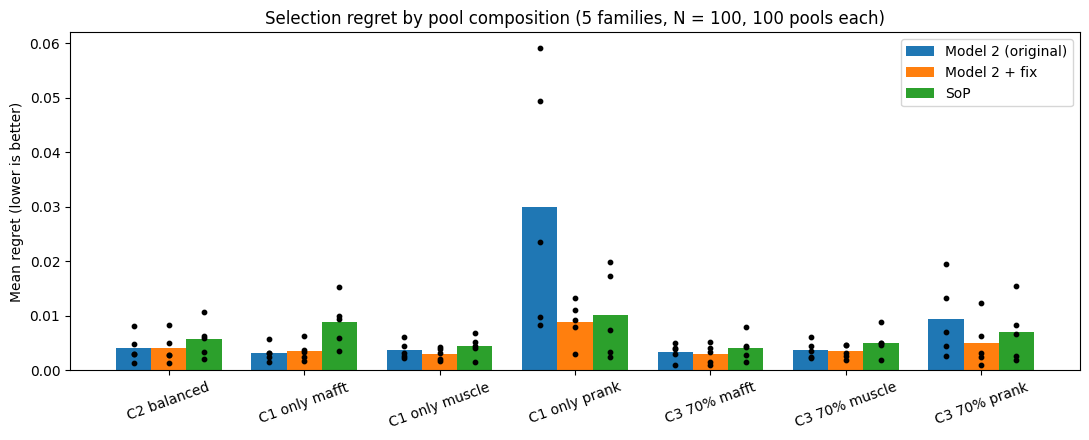

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

outdir = Path("/content/drive/MyDrive/MSA_Model2_Project/results")
res = pd.read_csv(outdir / "partA_5families_raw.csv")
rng = np.random.default_rng(0)

def boot_ci(x, n=5000):
    x = np.asarray(x, float)
    m = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return x.mean(), np.quantile(m, 0.025), np.quantile(m, 0.975)

rows = []
for fid, g in res.groupby("family"):
    c2 = g[g.condition == "C2 balanced"]
    for cond, gc in g.groupby("condition"):
        # (a) failure: model regret in this condition minus C2 (independent pools)
        diff = gc["model_regret"].to_numpy() - rng.choice(c2["model_regret"].to_numpy(), len(gc))
        fm, fl, fh = boot_ci(diff)
        # (b) fix effect: original minus fixed, same pools (paired)
        xm, xl, xh = boot_ci(gc["model_regret"] - gc["fixed_regret"])
        # (c) model vs SoP: SoP minus model, same pools (paired)
        sm, sl, sh = boot_ci(gc["sop_regret"] - gc["model_regret"])
        rows.append(dict(family=fid, condition=cond,
                         worse_than_C2=f"{fm:.4f} [{fl:.4f}, {fh:.4f}]",
                         fix_gain=f"{xm:.4f} [{xl:.4f}, {xh:.4f}]",
                         model_beats_sop=f"{sm:.4f} [{sl:.4f}, {sh:.4f}]",
                         failure_sig=fl > 0, fix_helps=xl > 0, fix_hurts=xh < 0,
                         model_beats_sop_sig=sl > 0, sop_beats_model_sig=sh < 0))
stats = pd.DataFrame(rows)
stats.to_csv(outdir / "partA_stats.csv", index=False)

print("=== Families (out of 5) with a significant effect, per condition ===")
print(stats.groupby("condition")[["failure_sig", "fix_helps", "fix_hurts",
                                  "model_beats_sop_sig", "sop_beats_model_sig"]].sum().to_string())

# Figure: mean regret per condition, averaged over families, with each family as a dot
fam_means = res.groupby(["condition", "family"])[["model_regret", "fixed_regret", "sop_regret"]].mean()
order = ["C2 balanced", "C1 only mafft", "C1 only muscle", "C1 only prank",
         "C3 70% mafft", "C3 70% muscle", "C3 70% prank"]
methods = [("model_regret", "Model 2 (original)"), ("fixed_regret", "Model 2 + fix"), ("sop_regret", "SoP")]
x = np.arange(len(order)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (col, label) in enumerate(methods):
    means = [fam_means.loc[c, col].mean() for c in order]
    ax.bar(x + (i - 1) * w, means, w, label=label)
    for j, c in enumerate(order):
        ax.scatter(np.full(5, x[j] + (i - 1) * w), fam_means.loc[c, col], s=10, color="black", zorder=3)
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20)
ax.set_ylabel("Mean regret (lower is better)")
ax.set_title("Selection regret by pool composition (5 families, N = 100, 100 pools each)")
ax.legend(); plt.tight_layout()
plt.savefig(outdir / "fig_partA_regret.png", dpi=200); plt.show()

## 10. Figures 1 and 2
Regenerates the two manuscript figures from the per-pool results. Output: `results/Figure1_regret_by_composition.png` and `results/Figure2_prank_only_per_dataset.png`.

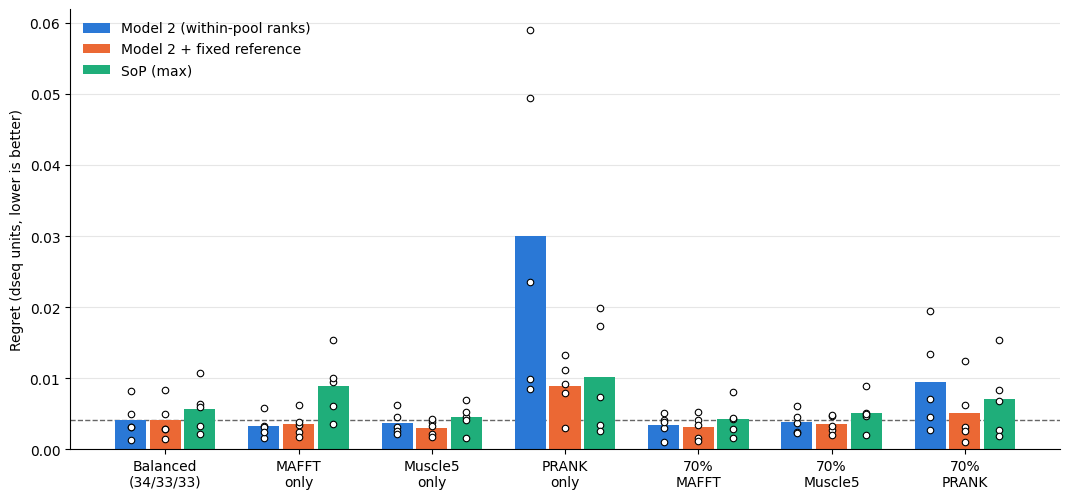

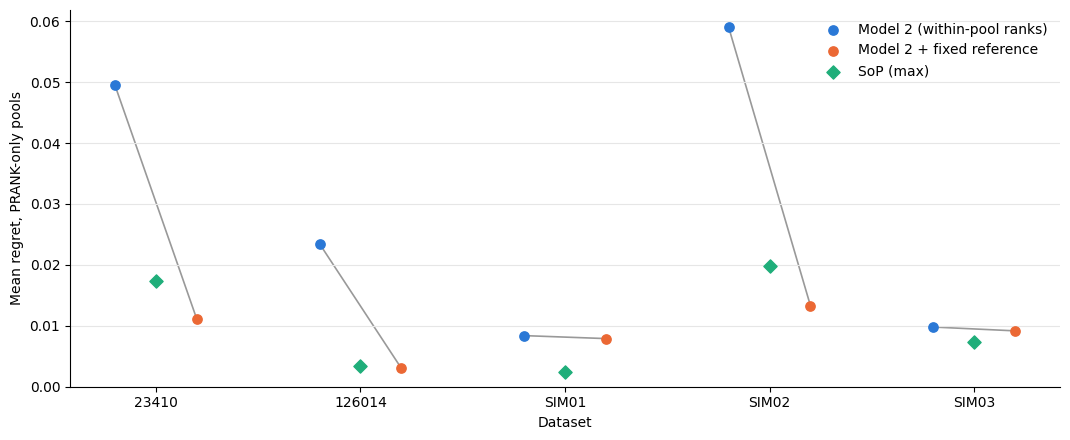

In [3]:
# Figures 1 and 2 of the manuscript, from the per-pool results
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

outdir = Path("/content/drive/MyDrive/MSA_Model2_Project/results")
res = pd.read_csv(outdir / "partA_5families_raw.csv")
res["family"] = res["family"].astype(str)
means = res.groupby(["condition", "family"])[["model_regret", "fixed_regret", "sop_regret"]].mean()

order = ["C2 balanced", "C1 only mafft", "C1 only muscle", "C1 only prank",
         "C3 70% mafft", "C3 70% muscle", "C3 70% prank"]
labels = ["Balanced\n(34/33/33)", "MAFFT\nonly", "Muscle5\nonly", "PRANK\nonly",
          "70%\nMAFFT", "70%\nMuscle5", "70%\nPRANK"]
methods = [("model_regret", "Model 2 (within-pool ranks)", "#2a78d6"),
           ("fixed_regret", "Model 2 + fixed reference", "#eb6834"),
           ("sop_regret", "SoP (max)", "#1fae7a")]

# Figure 1: mean regret per condition, each dataset as an open dot
x = np.arange(len(order)); w = 0.26
fig, ax = plt.subplots(figsize=(10.8, 5.1))
for i, (col, lab, colr) in enumerate(methods):
    xs = x + (i - 1) * w
    ax.bar(xs, [means.loc[c, col].mean() for c in order], w * 0.9, color=colr, label=lab, zorder=2)
    for j, c in enumerate(order):
        ax.scatter(np.full(len(means.loc[c]), xs[j]), means.loc[c, col], s=22,
                   facecolors="white", edgecolors="black", linewidths=0.8, zorder=3)
ax.axhline(means.loc["C2 balanced", "model_regret"].mean(), ls="--", c="0.4", lw=1, zorder=1)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Regret (dseq units, lower is better)")
ax.grid(axis="y", color="0.9", zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left"); plt.tight_layout()
plt.savefig(outdir / "Figure1_regret_by_composition.png", dpi=200); plt.show()

# Figure 2: PRANK-only pools per dataset, original vs fixed reference, with SoP
fams = ["23410", "126014", "SIM01", "SIM02", "SIM03"]
p = means.loc["C1 only prank"]
fig, ax = plt.subplots(figsize=(10.8, 4.5))
for k, f in enumerate(fams):
    ax.plot([k - 0.2, k + 0.2], [p.loc[f, "model_regret"], p.loc[f, "fixed_regret"]], c="0.6", lw=1.2, zorder=1)
    ax.scatter(k - 0.2, p.loc[f, "model_regret"], c=methods[0][2], s=45, zorder=2, label=methods[0][1] if k == 0 else None)
    ax.scatter(k + 0.2, p.loc[f, "fixed_regret"], c=methods[1][2], s=45, zorder=2, label=methods[1][1] if k == 0 else None)
    ax.scatter(k, p.loc[f, "sop_regret"], c=methods[2][2], marker="D", s=45, zorder=2, label=methods[2][1] if k == 0 else None)
ax.set_xticks(range(len(fams))); ax.set_xticklabels(fams); ax.set_xlabel("Dataset")
ax.set_ylabel("Mean regret, PRANK-only pools"); ax.set_ylim(bottom=0)
ax.grid(axis="y", color="0.9", zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right"); plt.tight_layout()
plt.savefig(outdir / "Figure2_prank_only_per_dataset.png", dpi=200); plt.show()


## 11. Implementation check and reference without PRANK
A new draw of 100 pools per dataset for the balanced, PRANK-only and 70% PRANK conditions (1,500 pools). Check A ranks each pool against itself, which must reproduce the original predictions. Check B uses a reference of the 800 MAFFT and Muscle5 candidates only. Output: `results/check_A_equivalence.csv` and `results/check_B_cheap_reference.csv` (Section 3.5).

In [ ]:
import os, sys
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from scipy.stats import spearmanr

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
REPO = proj / "sp_alternative"
os.chdir(REPO); sys.path.insert(0, str(REPO))
from dl_model.data_processing.group_aware_zscore_scaler import GroupAwareScalerZ
scaler = GroupAwareScalerZ(mode="rank", use_global=False)
scaler.load(str(REPO / "dl_model/input/orthomam_model2/scaler_0_mode1_dseq_from_true.pkl"))
model = tf.keras.models.load_model(
    REPO / "dl_model/input/orthomam_model2/regressor_model_0_mode1_dseq_from_true.keras", compile=False)
FEATS = list(scaler.feature_names)

def source_of(c):
    c = str(c).lower()
    return "muscle" if c.startswith("muscle") else "prank" if c.startswith("prank") else \
           "baliphy" if c.startswith("bali_phy") else "default" if c.startswith("msa.") else "mafft"
def load(path, fid):
    df = pd.read_csv(path, low_memory=False).drop(columns=["rf_from_true"], errors="ignore")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    df["code"] = df["code"].astype(str); df = df[df["code"] != fid].copy()
    df["source"] = df["code"].map(source_of)
    return df[df["source"].isin(["mafft", "prank", "muscle"])].reset_index(drop=True)
fam = {"23410": load(REPO / "example_data/features/groups_final/unified_stats_23410.csv", "23410"),
       "126014": load(proj / "126014_features_recovered.csv", "126014")}
for f in ["SIM01", "SIM02", "SIM03"]:
    fam[f] = load(proj / "sim_families" / f / f"{f}_features.csv", f)

def pred_within(pool):
    X = pool[FEATS].copy(); X["code1"] = "pool"
    return model(scaler.transform(X).astype("float32"), training=False).numpy().ravel()
def pred_fixed(pool, ref_sorted):
    C = pool[FEATS].to_numpy(float); out = np.empty_like(C, dtype=np.float32); n = len(ref_sorted)
    for j in range(C.shape[1]):
        out[:, j] = (np.searchsorted(ref_sorted[:, j], C[:, j], "left") +
                     np.searchsorted(ref_sorted[:, j], C[:, j], "right")) / 2 / n
    return model(out, training=False).numpy().ravel()

conds = {"C2 balanced": {"mafft": 34, "prank": 33, "muscle": 33},
         "C1 only prank": {"prank": 100},
         "C3 70% prank": {"prank": 70, "mafft": 15, "muscle": 15}}
rng = np.random.default_rng(2026)
eq_rows, rows = [], []
for fid, df in fam.items():
    ref_all = np.sort(df[FEATS].to_numpy(float), axis=0)
    ref_cheap = np.sort(df[df.source.isin(["mafft", "muscle"])][FEATS].to_numpy(float), axis=0)
    for cname, counts in conds.items():
        for rep in range(100):
            pool = pd.concat([df[df.source == s].sample(n=k, random_state=int(rng.integers(1e9)))
                              for s, k in counts.items()], ignore_index=True)
            d = pool["dseq_from_true"].to_numpy(float); best = d.min()
            p0 = pred_within(pool)
            # Check A: fixed ranking with reference = the pool itself
            pself = pred_fixed(pool, np.sort(pool[FEATS].to_numpy(float), axis=0))
            eq_rows.append(dict(family=fid, condition=cname,
                                spearman=spearmanr(p0, pself).correlation,
                                same_pick=int(p0.argmin() == pself.argmin())))
            rows.append(dict(family=fid, condition=cname,
                             original=d[p0.argmin()] - best,
                             fixed_all=d[pred_fixed(pool, ref_all).argmin()] - best,
                             fixed_no_prank=d[pred_fixed(pool, ref_cheap).argmin()] - best))
    print("done", fid)

eq = pd.DataFrame(eq_rows); res = pd.DataFrame(rows)
outdir = proj / "results"
eq.to_csv(outdir / "check_A_equivalence.csv", index=False)
res.to_csv(outdir / "check_B_cheap_reference.csv", index=False)

print("\n=== Check A: reference = pool vs original within-pool ranking ===")
print(f"median Spearman: {eq.spearman.median():.4f} | min: {eq.spearman.min():.4f} | same pick: {eq.same_pick.mean():.1%}")
print("\n=== Check B: mean regret (lower is better) ===")
tab = res.groupby(["condition", "family"])[["original", "fixed_all", "fixed_no_prank"]].mean()
print(tab.round(4).to_string())
print("\nMean over 5 datasets:")
print(res.groupby("condition")[["original", "fixed_all", "fixed_no_prank"]].mean().round(4).to_string())

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.5.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


done 23410
done 126014
done SIM01
done SIM02
done SIM03

=== Check A: reference = pool vs original within-pool ranking ===
median Spearman: 1.0000 | min: 0.9998 | same pick: 99.4%

=== Check B: mean regret (lower is better) ===
                      original  fixed_all  fixed_no_prank
condition     family                                     
C1 only prank 126014    0.0228     0.0023          0.0013
              23410     0.0472     0.0114          0.0110
              SIM01     0.0114     0.0123          0.0180
              SIM02     0.0581     0.0123          0.0155
              SIM03     0.0093     0.0102          0.0199
C2 balanced   126014    0.0028     0.0026          0.0040
              23410     0.0034     0.0031          0.0038
              SIM01     0.0093     0.0090          0.0089
              SIM02     0.0016     0.0016          0.0016
              SIM03     0.0041     0.0041          0.0040
C3 70% prank  126014    0.0186     0.0025          0.0065
              2341

## 12. Package the supplementary material
Copies the result tables, feature tables and simulation files into `CMPS355_Supplementary_Material.zip` on Drive.

In [ ]:
from pathlib import Path
import shutil

from google.colab import drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

proj = Path("/content/drive/MyDrive/MSA_Model2_Project")
out = Path("/content/Supplementary_Material"); shutil.rmtree(out, ignore_errors=True)
(out / "simulation").mkdir(parents=True); (out / "feature_tables").mkdir(); (out / "results").mkdir()

files = {
    proj / "results/partA_stats.csv":                out / "Supplementary_Table_S1_bootstrap_intervals.csv",
    proj / "results/partA_5families_raw.csv":        out / "results/per_pool_results_3500.csv",
    proj / "results/partA_5families_summary.csv":    out / "results/per_dataset_condition_means.csv",
    proj / "results/check_A_equivalence.csv":        out / "results/check_A_implementation.csv",
    proj / "results/check_B_cheap_reference.csv":    out / "results/check_B_reference_without_PRANK.csv",
    proj / "126014_features_recovered.csv":          out / "feature_tables/126014_features.csv",
    proj / "sp_alternative/example_data/features/groups_final/unified_stats_23410.csv":
                                                     out / "feature_tables/23410_features.csv",
}
for fid in ["SIM01", "SIM02", "SIM03"]:
    d = proj / "sim_families" / fid
    files[d / "control.txt"] = out / f"simulation/{fid}_indelible_control.txt"
    files[d / "meta.json"] = out / f"simulation/{fid}_settings_and_seed.json"
    files[d / "tree.txt"] = out / f"simulation/{fid}_tree.txt"
    files[d / f"{fid}_features.csv"] = out / f"feature_tables/{fid}_features.csv"

missing = []
for src, dst in files.items():
    if src.exists(): shutil.copy(src, dst)
    else: missing.append(str(src))

zip_path = shutil.make_archive(str(proj / "CMPS355_Supplementary_Material"), "zip", out)
print("Zip saved to Drive:", zip_path)
print("Missing:", missing if missing else "none")

Zip saved to Drive: /content/drive/MyDrive/MSA_Model2_Project/CMPS355_Supplementary_Material.zip
Missing: none
